# bangla-summarizer-pro — full fine-tune of Gemma-3-1B for Bangla summarization

**Kaggle, GPU T4.** Settings → Accelerator → **GPU T4**, Internet → **On**.
HF **write** token as a Kaggle Secret named `HF_TOKEN` (Add-ons → Secrets).
About 4 hours. Use `Save Version → Save & Run All (Commit)` so a closed tab cannot kill it.

Same recipe as `bangla-gemma-pro` — full fine-tune, every parameter, free T4 — but the task
is abstractive summarization of Bangla news on
[XL-Sum](https://huggingface.co/datasets/csebuetnlp/xlsum), 8,102 BBC Bangla
article–summary pairs written by professionals.

### Why this task should suit fine-tuning better than instruction following

The earlier Bangla run improved perplexity sharply but barely moved multiple-choice
accuracy, because those benchmarks sit near their chance floor at 1B. Summarization has no
chance floor: the model either reproduces the reference's content and register or it does
not, and chrF measures that directly. It is also a **form** task — base models asked to
summarize write too much, in the wrong register — and form is exactly what supervised
fine-tuning fixes.

### Metrics

| | why |
|---|---|
| **chrF++** | character n-gram F-score; works on Bangla morphology where word-level ROUGE does not |
| **ROUGE-L** | reported for comparability, with its Bangla caveat stated |
| **Lead-3** | copy the first three sentences — the standard check that a summarizer does more than truncate |
| **Base zero-shot** | the comparison that matters: can Gemma-3-1B already do this? |
| **Length ratio** | summaries that match the reference length score better for reasons unrelated to quality |

In [1]:
import subprocess, os, shutil
try:
    print(subprocess.check_output(["nvidia-smi", "--query-gpu=name,memory.total",
                                   "--format=csv,noheader"]).decode().strip())
except Exception:
    print("No GPU — Settings > Accelerator > GPU T4")
print("disk free:", round(shutil.disk_usage("/kaggle/working").free/1e9, 1), "GB")
shutil.rmtree("/kaggle/working/outputs", ignore_errors=True)

Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
disk free: 20.9 GB


In [2]:
!pip install -q unsloth
!pip install -q --no-deps --upgrade git+https://github.com/unslothai/unsloth.git
!pip install -q sacrebleu rouge_score matplotlib
print("installed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.4/30.4 MB 70.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 51.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 99.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 101.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 90.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 14.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing

## 1. Configuration

**Why batch 2 at 512 and not batch 1 at 768.** Both are about a thousand token-positions
per step, so memory is similar — but batch 1 means 16 forward/backward passes per optimizer
step instead of 8, and each carries the same fixed cost in kernel launches, Python overhead
and gradient-checkpointing recompute while doing half the work. The companion run measured
14.90 GB at batch 2 × 512, so this shape is known to fit.

**Why 500 steps.** 500 × 16 = 8,000 examples, which is one pass over the training split.
At 400 steps the model would never see about 20% of the data.

**Why not `packing=True`.** Packing concatenates examples to fill the window, which would
speed things up — but it also merges turn boundaries, and `train_on_responses_only` finds
the supervised region by locating those boundaries. The two do not combine safely, and a
silently mis-masked loss is worse than a slower run.

In [3]:
import gc, re, json, time, random, inspect, math
import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from unsloth import FastModel, is_bfloat16_supported
from unsloth.chat_templates import train_on_responses_only
from datasets import load_dataset
from trl import SFTTrainer

BASE_MODEL = "unsloth/gemma-3-1b-it"
UPSTREAM   = "google/gemma-3-1b-it"
MODEL_NAME = "bangla-summarizer-pro"

MAX_SEQ   = 512         # the shape that measured 14.90 GB on this GPU
BATCH     = 2           # batch 1 leaves the tensor cores idle and doubles the micro-steps
ACCUM     = 8           # effective 16, same as before
MAX_STEPS = 500         # 500 x 16 = 8,000 ~= one full epoch over the training split
LR        = 1e-5        # full fine-tune: an order below LoRA's 2e-4
SEED      = 3407

EVAL_N   = 200          # generation is the slow part
MAX_NEW  = 128          # XL-Sum summaries are one or two sentences

WORK   = "/kaggle/working"
SAVE   = f"{WORK}/{MODEL_NAME}"
MERGED = f"{WORK}/{MODEL_NAME}-merged"
GGUF   = f"{WORK}/{MODEL_NAME}-GGUF"
ASSETS = f"{SAVE}/assets"
for d in (SAVE, ASSETS):
    os.makedirs(d, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
GPU, BF16 = torch.cuda.get_device_name(0), is_bfloat16_supported()
print(f"{GPU} | bfloat16 {BF16}")

plt.rcParams.update({"figure.dpi":130,"savefig.dpi":130,"savefig.bbox":"tight","font.size":10,
                     "axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"figure.facecolor":"white"})
C_LEAD, C_BASE, C_TUNED = "#cbd5e1", "#94a3b8", "#0ea5e9"

def vram(): return torch.cuda.max_memory_allocated()/1e9
def clear(): gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

from kaggle_secrets import UserSecretsClient
HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
from huggingface_hub import login, whoami, create_repo, upload_folder
login(token=HF_TOKEN)
HF_USERNAME = whoami()["name"]
REPO_ID   = f"{HF_USERNAME}/{MODEL_NAME}"
GGUF_REPO = f"{HF_USERNAME}/{MODEL_NAME}-GGUF"
print(f"{HF_USERNAME} -> {REPO_ID}")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
Tesla T4 | bfloat16 False
emonHasan01 -> emonHasan01/bangla-summarizer-pro


## 2. XL-Sum Bengali

`csebuetnlp/xlsum` is script-based and recent `datasets` releases refuse to execute loading
scripts. Four strategies are tried in order so the cell works whichever of them is
available, and it prints which one succeeded.

In [4]:
def load_xlsum():
    attempts = [
        ("csebuetnlp/xlsum, config bengali",
         lambda: load_dataset("csebuetnlp/xlsum", "bengali")),
        ("GEM/xlsum, config bengali",
         lambda: load_dataset("GEM/xlsum", "bengali")),
        ("csebuetnlp/xlsum parquet branch",
         lambda: load_dataset("parquet", data_files={
             s: f"hf://datasets/csebuetnlp/xlsum@refs%2Fconvert%2Fparquet/bengali/{s}/*.parquet"
             for s in ("train", "validation", "test")})),
        ("csebuetnlp/xlsum parquet, flat layout",
         lambda: load_dataset("parquet", data_files={
             s: f"hf://datasets/csebuetnlp/xlsum@refs%2Fconvert%2Fparquet/bengali/bengali-{s}.parquet"
             for s in ("train", "validation", "test")})),
    ]
    for label, fn in attempts:
        try:
            ds = fn()
            print(f"loaded via: {label}")
            return ds
        except Exception as e:
            print(f"  {label} failed ({type(e).__name__}: {str(e)[:80]})")
    raise RuntimeError("Could not load XL-Sum Bengali by any route.")

raw = load_xlsum()
print(raw)

cols = raw["train"].column_names
TEXT_COL = next(c for c in ["text", "article", "document", "source"] if c in cols)
SUM_COL  = next(c for c in ["summary", "target", "abstract"] if c in cols)
print(f"\narticle column: {TEXT_COL} | summary column: {SUM_COL}")

train_raw = raw["train"].shuffle(seed=SEED)
test_raw  = raw["test"].shuffle(seed=SEED).select(range(min(EVAL_N, len(raw["test"]))))

ex = train_raw[0]
print(f"\n--- article ({len(ex[TEXT_COL].split())} words) ---\n{ex[TEXT_COL][:400]}")
print(f"\n--- reference summary ({len(ex[SUM_COL].split())} words) ---\n{ex[SUM_COL]}")

a_words = [len(r[TEXT_COL].split()) for r in train_raw.select(range(500))]
s_words = [len(r[SUM_COL].split())  for r in train_raw.select(range(500))]
REF_WORDS = float(np.mean(s_words))
print(f"\narticle : median {int(np.median(a_words))} words, 90th {int(np.percentile(a_words,90))}")
print(f"summary : median {int(np.median(s_words))} words, mean {REF_WORDS:.1f}")

README.md:   0%|          | 0.00/14.6k [00:00<?, ?B/s]

xlsum.py:   0%|          | 0.00/4.55k [00:00<?, ?B/s]

  csebuetnlp/xlsum, config bengali failed (RuntimeError: Dataset scripts are no longer supported, but found xlsum.py)


README.md:   0%|          | 0.00/30.1k [00:00<?, ?B/s]

xlsum.py:   0%|          | 0.00/4.82k [00:00<?, ?B/s]

...

bengali/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

loaded via: csebuetnlp/xlsum parquet branch
DatasetDict({
    train: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 8102
    })
    validation: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 1012
    })
    test: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 1012
    })
})

article column: text | summary column: summary

--- article (718 words) ---
ইতালির উত্তরাঞ্চলের মানুষ করোনভাইরাসে সবচেয়ে বেশি আক্রান্ত হয়েছে। নতুন করোনাভাইরাসের সংক্রমণে এখনও প্রতিদিন আক্রান্তের সংখ্যা গড়ে একশ জন করে বৃদ্ধি পাচ্ছে। এই বিপুল পরিমাণ রোগীদের চিকিৎসা দেয়ার জন্য হাসপাতালের পর্যাপ্ত বিছানার ব্যবস্থা করতে রীতিমত সংগ্রাম করে যাচ্ছেন তারা। যুদ্ধ বিগ্রহ ছাড়া কোন দেশের এমন পরিস্থিতি ভাবা যায় না। উত্তরাঞ্চলীয় লম্বার্ডিয়া অঞ্চলের বার্গামো শহরের একটি হাসপাতালের

--- reference summary (28 words) ---
ইটালিতে করোনাভাইরাসের বিরুদ্ধে লড়াইয়ে প্রথম সারিতে থাকা চিকিৎসকরা বলছেন যে, এত রো

## 3. Prompt and tokenization

**The article is truncated, never the summary.** A summary cut off halfway teaches the
model to stop mid-sentence, which is far worse than feeding it a shorter article.

In [5]:
model, tokenizer = FastModel.from_pretrained(
    model_name      = BASE_MODEL,
    max_seq_length  = MAX_SEQ,
    dtype           = None,
    load_in_4bit    = False,
    full_finetuning = True,
)
N_PARAMS  = sum(p.numel() for p in model.parameters())
TRAINABLE = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"{N_PARAMS/1e9:.2f}B params | trainable {100*TRAINABLE/N_PARAMS:.1f}% | {vram():.2f} GB")
assert TRAINABLE > 0.9 * N_PARAMS, "full_finetuning=True did not take effect"

from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(tokenizer, chat_template="gemma-3")

SYSTEM_BN = "আপনি একজন দক্ষ সংবাদ সম্পাদক। বাংলা সংবাদ প্রতিবেদনের সংক্ষিপ্তসার লেখেন।"
INSTRUCT  = "নিচের সংবাদ প্রতিবেদনটির এক বা দুই বাক্যে সংক্ষিপ্তসার লিখুন।\n\n{article}"

def to_chat(article, summary=None):
    msgs = [{"role": "system", "content": SYSTEM_BN},
            {"role": "user", "content": INSTRUCT.format(article=article)}]
    if summary is not None:
        msgs.append({"role": "assistant", "content": summary})
    return msgs

def build(ex):
    """Trim the article so prompt + summary fits, leaving the summary whole.

    The token count is returned alongside the text so the filter below does not have to
    tokenize all 8,102 rows a second time.
    """
    summary = str(ex[SUM_COL]).strip()
    article = str(ex[TEXT_COL]).strip()
    sum_tok = len(tokenizer(summary, add_special_tokens=False)["input_ids"])
    overhead = 96                       # template, system prompt, instruction
    room = max(64, MAX_SEQ - sum_tok - overhead)
    art_ids = tokenizer(article, add_special_tokens=False)["input_ids"][:room]
    article = tokenizer.decode(art_ids, skip_special_tokens=True)
    text = tokenizer.apply_chat_template(to_chat(article, summary), tokenize=False)
    return {"text": text,
            "n_tok": len(tokenizer(text, add_special_tokens=False)["input_ids"])}

NPROC = max(2, min(4, os.cpu_count() or 2))
ds = train_raw.map(build, remove_columns=train_raw.column_names, num_proc=NPROC)
lens = ds["n_tok"]
print(f"\nsequence length after trimming: median {int(np.median(lens))}, "
      f"max {max(lens)}, over limit {sum(l > MAX_SEQ for l in lens)}")
ds = ds.filter(lambda e: e["n_tok"] <= MAX_SEQ, num_proc=NPROC)
ds = ds.remove_columns("n_tok")
print(f"kept {len(ds):,} of {len(train_raw):,}")

# The validation split was going unused. 300 rows give an eval-loss curve for almost no
# extra time, which is the only way to see whether the run starts overfitting.
eval_ds = (raw["validation"].shuffle(seed=SEED).select(range(min(300, len(raw["validation"]))))
           .map(build, remove_columns=raw["validation"].column_names, num_proc=NPROC)
           .filter(lambda e: e["n_tok"] <= MAX_SEQ, num_proc=NPROC)
           .remove_columns("n_tok"))
print(f"validation for eval loss: {len(eval_ds)} rows")
print("\n--- formatted example ---\n", ds[0]["text"][:700])

==((====))==  Unsloth 2026.10.6: Fast Gemma3 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.
Unsloth: Not planning a device map; full finetuning does not use the quantized planner. Using `sequential`.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Using bfloat16 full finetuning which cuts memory usage by 50%.
To enable float32 training, use `float32_mixed_precision = True` during FastLanguageModel.from_pretrained


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


...

Filter (num_proc=4):   0%|          | 0/8102 [00:00<?, ? examples/s]

kept 8,102 of 8,102


Map (num_proc=4):   0%|          | 0/300 [00:00<?, ? examples/s]

Filter (num_proc=4):   0%|          | 0/300 [00:00<?, ? examples/s]

validation for eval loss: 300 rows

--- formatted example ---
 <bos><start_of_turn>user
আপনি একজন দক্ষ সংবাদ সম্পাদক। বাংলা সংবাদ প্রতিবেদনের সংক্ষিপ্তসার লেখেন।

নিচের সংবাদ প্রতিবেদনটির এক বা দুই বাক্যে সংক্ষিপ্তসার লিখুন।

ইতালির উত্তরাঞ্চলের মানুষ করোনভাইরাসে সবচেয়ে বেশি আক্রান্ত হয়েছে। নতুন করোনাভাইরাসের সংক্রমণে এখনও প্রতিদিন আক্রান্তের সংখ্যা গড়ে একশ জন করে বৃদ্ধি পাচ্ছে। এই বিপুল পরিমাণ রোগীদের চিকিৎসা দেয়ার জন্য হাসপাতালের পর্যাপ্ত বিছানার ব্যবস্থা করতে রীতিমত সংগ্রাম করে যাচ্ছেন তারা। যুদ্ধ বিগ্রহ ছাড়া কোন দেশের এমন পরিস্থিতি ভাবা যায় না। উত্তরাঞ্চলীয় লম্বার্ডিয়া অঞ্চলের বার্গামো শহরের একটি হাসপাতালের নিবিড় পরিচর্যা ইউনিটের প্রধান ডা. ক্রিশ্চিয়ান সালারোলি ক্যুরিয়েরে ডেলা সেরা নামে এক সংবাদপত্রকে তার হাসপাতালের অভিজ্ঞতার কথা বলতে গিয


## 4. Evaluation harness

chrF++ is the primary measure. It compares character n-grams, so a Bangla word inflected
differently still scores partial credit — where word-level ROUGE would score zero. ROUGE-L
is reported alongside for comparability, with that caveat attached.

In [6]:
import sacrebleu
from rouge_score import rouge_scorer

CHRF = sacrebleu.CHRF(word_order=2)          # chrF++

class BanglaTokenizer:
    """rouge_score's default tokenizer strips every non-ASCII character, which deletes
    Bangla entirely and makes every ROUGE score exactly 0. This keeps Bangla letters,
    Latin letters and digits, and splits on whitespace."""
    _keep = re.compile(r"[^\u0980-\u09FF\w\s]", re.UNICODE)
    def tokenize(self, text):
        return [t for t in self._keep.sub(" ", str(text)).lower().split() if t]

BN_TOK = BanglaTokenizer()
RSCORE = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=False, tokenizer=BN_TOK)

# fail loudly rather than reporting a meaningless 0.00 in the card
_probe = RSCORE.score("ঢাকায় ভারী বৃষ্টি হয়েছে।", "ঢাকায় ভারী বৃষ্টি হয়েছে।")["rougeL"].fmeasure
assert _probe > 0.9, (
    f"ROUGE tokenizer is dropping Bangla (identical strings scored {_probe}). "
    "Check BanglaTokenizer before trusting any ROUGE number.")
print(f"ROUGE tokenizer check: identical Bangla strings score {_probe:.2f}")

EV_ART = [str(r[TEXT_COL]).strip() for r in test_raw]
EV_REF = [str(r[SUM_COL]).strip()  for r in test_raw]

def score_summaries(preds, refs):
    chrf = CHRF.corpus_score(preds, [refs]).score
    rl = float(np.mean([RSCORE.score(r, p)["rougeL"].fmeasure for p, r in zip(preds, refs)]))
    return {"chrf": round(chrf, 2),
            "rougeL": round(100*rl, 2),
            "mean_words": round(float(np.mean([len(p.split()) for p in preds])), 1)}

def lead_k(article, k=3):
    parts = re.split(r"(?<=[।!?])\s+", article.strip())
    return " ".join(parts[:k]).strip() or article[:300]

@torch.no_grad()
def summarize(m, articles, tag, batch_size=16):
    """Inference needs no gradients or optimizer state, so it tolerates a far larger batch
    than training. If the GPU disagrees, halve and retry rather than losing the run."""
    from unsloth import FastLanguageModel
    try:
        FastLanguageModel.for_inference(m)
    except Exception:
        m.eval()
    side = tokenizer.padding_side
    tokenizer.padding_side = "left"
    outs, t0 = [], time.time()
    for i in range(0, len(articles), batch_size):
        chunk = articles[i:i+batch_size]
        prompts = []
        for a in chunk:
            ids = tokenizer(a, add_special_tokens=False)["input_ids"][:MAX_SEQ-160]
            prompts.append(tokenizer.apply_chat_template(
                to_chat(tokenizer.decode(ids, skip_special_tokens=True)),
                tokenize=False, add_generation_prompt=True))
        enc = tokenizer(prompts, return_tensors="pt", padding=True,
                        add_special_tokens=False).to("cuda")
        try:
            g = m.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False,
                           repetition_penalty=1.1, use_cache=True,
                           pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id)
        except torch.cuda.OutOfMemoryError:
            if batch_size <= 2:
                raise
            torch.cuda.empty_cache()
            print(f"\n  OOM at batch {batch_size}, retrying the whole pass at "
                  f"{batch_size//2}" + " "*20)
            tokenizer.padding_side = side
            return summarize(m, articles, tag, batch_size // 2)
        for j in range(len(chunk)):
            outs.append(tokenizer.decode(g[j][enc["input_ids"].shape[1]:],
                                         skip_special_tokens=True).strip())
        print(f"  {tag} {min(i+batch_size,len(articles))}/{len(articles)} "
              f"({time.time()-t0:.0f}s)", end="\r")
    tokenizer.padding_side = side
    print(f"  {tag} done in {time.time()-t0:.0f}s" + " "*20)
    return outs

ROUGE tokenizer check: identical Bangla strings score 1.00


## 5. Two baselines, before any training

**Lead-3** copies the first three sentences. On news it is a famously strong baseline and
the standard check that a summarizer is doing more than truncating.

**Gemma-3-1B zero-shot** is the comparison that decides whether this fine-tune was worth
the GPU hours.

In [7]:
LEAD3_OUT = [lead_k(a) for a in EV_ART]
LEAD3 = score_summaries(LEAD3_OUT, EV_REF)
print("lead-3      :", LEAD3)

clear()
BASE_OUT = summarize(model, EV_ART, "base")
BASE = score_summaries(BASE_OUT, EV_REF)
print("base 0-shot :", BASE)
print(f"\nreference mean length: {REF_WORDS:.0f} words")
print("\n--- one base output ---\n", BASE_OUT[0][:400])

json.dump({"lead3": LEAD3, "base": BASE, "ref_words": REF_WORDS,
           "base_out": BASE_OUT[:20]},
          open(f"{SAVE}/baseline.json", "w"), indent=2, ensure_ascii=False)
print(f"\nbaseline saved to {SAVE}/baseline.json")
clear()

lead-3      : {'chrf': 26.02, 'rougeL': 10.34, 'mean_words': 51.6}


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  base done in 152s                    
base 0-shot : {'chrf': 22.78, 'rougeL': 8.23, 'mean_words': 46.2}

reference mean length: 23 words

--- one base output ---
 বরফের ভেতর লুকানো ১২০ বছরের পুরোনো একটি ফ্রুটকেক কেপ এডেয়ার অঞ্চলে পাওয়া গেছে। এটি ব্রিটিশ অভিযাত্রিক রবার্ট ফ্যালকনের তৈরি এবং ১৯১১ সালে ক্যাপ্টেন স্কট এর কাজে ব্যবহৃত হয়েছিল। এই কেকটি নিয়ে গবেষণা করছেন বিজ্ঞানীরা।

baseline saved to /kaggle/working/bangla-summarizer-pro/baseline.json


## 6. Trainer

Loss on the assistant turn only, so the gradient is not spent regenerating the article.

In [8]:
try:
    from trl import SFTConfig
    CFG = SFTConfig
except ImportError:
    from transformers import TrainingArguments as CFG
_P = set(inspect.signature(CFG.__init__).parameters)

wanted = dict(
    per_device_train_batch_size=BATCH, gradient_accumulation_steps=ACCUM,
    warmup_steps=30, max_steps=MAX_STEPS, learning_rate=LR,
    fp16=not BF16, bf16=BF16, logging_steps=20, optim="adamw_8bit",
    weight_decay=0.01, lr_scheduler_type="cosine", max_grad_norm=1.0,
    seed=SEED, output_dir=f"{WORK}/outputs", report_to="none",
    save_strategy="no", gradient_checkpointing=True,
    eval_strategy="steps", evaluation_strategy="steps",   # name differs across versions
    eval_steps=100, per_device_eval_batch_size=BATCH,
    max_seq_length=MAX_SEQ, dataset_text_field="text",
    dataset_num_proc=2, packing=False,
)
kw = {k: v for k, v in wanted.items() if k in _P}
if "eval_strategy" in kw and "evaluation_strategy" in kw:
    kw.pop("evaluation_strategy")          # never pass both spellings
extra = {k: wanted[k] for k in ["max_seq_length","dataset_text_field",
                                "dataset_num_proc","packing"] if k not in _P}
dropped = sorted(set(wanted) - set(kw) - set(extra))
if dropped:
    print("not supported by this version, skipped:", dropped)

trainer = SFTTrainer(model=model, tokenizer=tokenizer, train_dataset=ds,
                     eval_dataset=eval_ds, args=CFG(**kw), **extra)
trainer = train_on_responses_only(
    trainer,
    instruction_part="<start_of_turn>user\n",
    response_part="<start_of_turn>model\n")

lab = np.array(trainer.train_dataset[0]["labels"])
sup = int((lab != -100).sum())
print(f"\n{sup}/{len(lab)} tokens supervised ({sup/len(lab):.1%})")
print("supervised begins:", repr(tokenizer.decode([t for t in lab if t != -100][:40])))
assert 0 < sup < len(lab), "response-only masking failed"

not supported by this version, skipped: ['evaluation_strategy']
Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/8102 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/300 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map (num_proc=2):   0%|          | 0/8102 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/300 [00:00<?, ? examples/s]


39/459 tokens supervised (8.5%)
supervised begins: 'ইটালিতে করোনাভাইরাসের বিরুদ্ধে লড়াইয়ে প্রথম সারিতে থাকা চিকিৎসকরা বলছেন যে, এত রোগীর ভিড় যে কাদের তারা বাঁচানোর চেষ্টা করবেন এবং কাদের ফেলে রাখবেন তা তাদেরকে বেছে নিতে হচ্ছে।<end_of_turn>'


## 7. Train

Roughly 3 hours. Use Commit mode so a closed browser tab cannot end the session.

In [9]:
free = shutil.disk_usage(WORK).free/1e9
print(f"disk free: {free:.1f} GB")
assert free > 8, "need at least 8 GB free"

clear()
t0 = time.time()
stats = trainer.train()
TRAIN_MIN = (time.time()-t0)/60
VRAM_TRAIN = vram()
CURVE = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
EVAL_CURVE = [(h["step"], h["eval_loss"]) for h in trainer.state.log_history
              if "eval_loss" in h]
print("eval loss:", [(s_, round(l, 4)) for s_, l in EVAL_CURVE])
print(f"\n{TRAIN_MIN:.0f} min | peak VRAM {VRAM_TRAIN:.2f} GB of 15.0 | "
      f"final loss {stats.training_loss:.4f}")
assert not np.isnan(stats.training_loss), "loss is NaN"

disk free: 20.9 GB


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 8,102 | Num Epochs = 1 | Total steps = 500
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 8 x 1) = 16
 "-____-"     Trainable parameters = 999,885,952 of 999,885,952 (100.00% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
100,2.902682,2.786445
200,2.749759,2.629990
300,2.695966,2.551110
400,2.683221,2.489990
500,2.662146,2.477070


Filter:   0%|          | 0/300 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma3TextModel's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


eval loss: [(100, 2.7864), (200, 2.63), (300, 2.5511), (400, 2.49), (500, 2.4771)]

184 min | peak VRAM 14.61 GB of 15.0 | final loss 2.8145


## 8. Evaluate

In [10]:
clear()
TUNED_OUT = summarize(model, EV_ART, "tuned")
TUNED = score_summaries(TUNED_OUT, EV_REF)

D_CHRF = TUNED["chrf"] - BASE["chrf"]
print(f"\n{'':20}{'chrF++':>9}{'ROUGE-L':>10}{'words':>8}")
for name, m in [("lead-3", LEAD3), ("base zero-shot", BASE), ("fine-tuned", TUNED)]:
    print(f"{name:20}{m['chrf']:9.2f}{m['rougeL']:10.2f}{m['mean_words']:8.1f}")
print(f"{'reference':20}{'':9}{'':10}{REF_WORDS:8.1f}")
print(f"\nchrF++ against base: {D_CHRF:+.2f}")

EXAMPLES = [{"article": EV_ART[i][:400], "reference": EV_REF[i],
             "lead3": LEAD3_OUT[i], "base": BASE_OUT[i], "tuned": TUNED_OUT[i]}
            for i in range(4)]
for e in EXAMPLES[:2]:
    print(f"\nREFERENCE : {e['reference'][:200]}")
    print(f"BASE      : {e['base'][:200]}")
    print(f"TUNED     : {e['tuned'][:200]}")

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  tuned done in 92s                    

                       chrF++   ROUGE-L   words
lead-3                  26.02     10.34    51.6
base zero-shot          22.78      8.23    46.2
fine-tuned              24.91     11.43    34.4
reference                                  23.3

chrF++ against base: +2.13

REFERENCE : বরফে ঢাকা এন্টার্কটিকায় হয়তো বিশ্বের সবচেয়ে বিরূপ প্রাকৃতিক পরিবেশ। কিন্তু ব্রিটিশ এক প্যাকেট ফ্রুটকেক ১০০ বছরেরও বেশি সময় ধরে তা সহজেই সামলেছে।
BASE      : বরফের ভেতর লুকানো ১২০ বছরের পুরোনো একটি ফ্রুটকেক কেপ এডেয়ার অঞ্চলে পাওয়া গেছে। এটি ব্রিটিশ অভিযাত্রিক রবার্ট ফ্যালকনের তৈরি এবং ১৯১১ সালে ক্যাপ্টেন স্কট এর কাজে ব্যবহৃত হয়েছিল। এই কেকটি নিয়ে গবেষণা ক
TUNED     : নরওয়ের একটি অভিযাত্রী দলের সদস্যরা এন্টার্কটিকায় যে একটি পুরনো কুঁড়েঘর খুঁজে পেয়েছেন তাতে তাদের হাতেই রাখা হয়েছে একটি প্রাচীন ফ্রুটকেক। এটি এখন এন্টার্কটিকার সবচেয়ে পুরনো একটি স্থাপনার অংশ হিসেব

REFERENCE : ইতালিতে অভিবাসীদের এক কেন্দ্রে একটি দু'বছরের শিশুর খৎনা করানোর সময় অতিরিক্ত রক্তক্ষরণ শুর

## 9. Charts

charts: ['length.png', 'loss.png', 'scores.png']


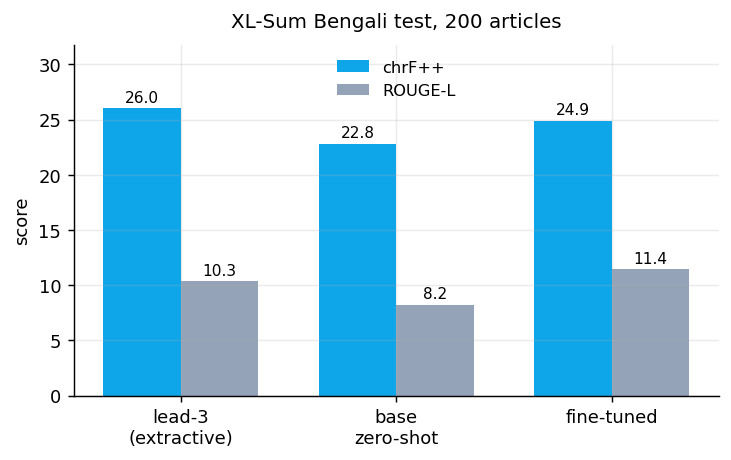

In [11]:
fig, ax = plt.subplots(figsize=(6.4, 3.5))
labels = ["lead-3\n(extractive)", "base\nzero-shot", "fine-tuned"]
x = np.arange(3); w = .36
cv = [LEAD3["chrf"], BASE["chrf"], TUNED["chrf"]]
rv = [LEAD3["rougeL"], BASE["rougeL"], TUNED["rougeL"]]
ax.bar(x-w/2, cv, w, label="chrF++", color=C_TUNED)
ax.bar(x+w/2, rv, w, label="ROUGE-L", color=C_BASE)
for xi, v in zip(x-w/2, cv): ax.text(xi, v+.6, f"{v:.1f}", ha="center", fontsize=8.5)
for xi, v in zip(x+w/2, rv): ax.text(xi, v+.6, f"{v:.1f}", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("score")
ax.set_ylim(0, max(cv+rv)*1.22)
ax.set_title(f"XL-Sum Bengali test, {len(EV_REF)} articles", fontsize=11, pad=10)
ax.legend(frameon=False, fontsize=9)
plt.savefig(f"{ASSETS}/scores.png"); plt.close()

fig, ax = plt.subplots(figsize=(5.4, 3.2))
lens_ = [LEAD3["mean_words"], BASE["mean_words"], TUNED["mean_words"], REF_WORDS]
bars = ax.bar(["lead-3","base","fine-tuned","reference"], lens_,
              color=[C_LEAD, C_BASE, C_TUNED, "#059669"], width=.55)
for b, v in zip(bars, lens_):
    ax.text(b.get_x()+b.get_width()/2, v+1, f"{v:.0f}", ha="center", fontsize=9)
ax.set_ylabel("mean words per summary")
ax.set_title("Length against the reference", fontsize=11, pad=10)
plt.savefig(f"{ASSETS}/length.png"); plt.close()

fig, ax = plt.subplots(figsize=(6.2, 3.1))
ax.plot([s for s,_ in CURVE], [l for _,l in CURVE], color=C_TUNED, lw=1.5, label="train")
if EVAL_CURVE:
    ax.plot([s for s,_ in EVAL_CURVE], [l for _,l in EVAL_CURVE], "o--",
            color="#dc2626", lw=1.5, ms=5, label="validation")
ax.set_xlabel("step"); ax.set_ylabel("loss (assistant turn only)")
ax.set_title("Training and validation loss", fontsize=11, pad=10)
ax.legend(frameon=False, fontsize=9)
plt.savefig(f"{ASSETS}/loss.png"); plt.close()
print("charts:", sorted(os.listdir(ASSETS)))

from IPython.display import Image, display
display(Image(f"{ASSETS}/scores.png"))

## 10. Save weights and GGUF

In [12]:
model.save_pretrained(SAVE); tokenizer.save_pretrained(SAVE)
try:
    model.save_pretrained_merged(MERGED, tokenizer, save_method="merged_16bit")
except Exception:
    shutil.copytree(SAVE, MERGED, dirs_exist_ok=True)
merged_gb = sum(os.path.getsize(f"{MERGED}/{f}") for f in os.listdir(MERGED)
                if os.path.isfile(f"{MERGED}/{f}"))/1e9
print(f"merged: {merged_gb:.2f} GB")

GGUF_OK, GGUF_FILES, GGUF_ERR = False, [], None
try:
    model.save_pretrained_gguf(GGUF, tokenizer, quantization_method=["q4_k_m", "q8_0"])
except Exception as e:
    GGUF_ERR = str(e)[:300]
    print("conversion raised:", GGUF_ERR)

import glob
found = sorted({p for d in [GGUF, GGUF+"_gguf", WORK]
                if os.path.isdir(d) for p in glob.glob(os.path.join(d, "*.gguf"))})
os.makedirs(GGUF, exist_ok=True)
for src_f in found:
    m = re.search(r"\.(Q\d[^.]*|F16|BF16)\.gguf$", os.path.basename(src_f), re.I)
    quant = m.group(1) if m else os.path.basename(src_f).split(".")[-2]
    dst = os.path.join(GGUF, f"{MODEL_NAME}.{quant}.gguf")
    if os.path.abspath(src_f) != os.path.abspath(dst):
        shutil.move(src_f, dst)
    GGUF_FILES.append(os.path.basename(dst))
for f in list(GGUF_FILES):
    if re.search(r"\.(F16|BF16)\.gguf$", f, re.I):
        os.remove(os.path.join(GGUF, f)); GGUF_FILES.remove(f)
GGUF_FILES = sorted(set(GGUF_FILES))
GGUF_OK = bool(GGUF_FILES)
for f in GGUF_FILES:
    print(f"  {f}: {os.path.getsize(os.path.join(GGUF,f))/1e9:.2f} GB")

json.dump({"chat_template": "gemma-3", "system": SYSTEM_BN, "instruction": INSTRUCT},
          open(f"{SAVE}/prompt_format.json", "w"), indent=2, ensure_ascii=False)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/bangla-summarizer-pro/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /kaggle/working/bangla-summarizer-pro.


Unsloth: Saving full fine-tuned model to '/kaggle/working/bangla-summarizer-pro-merged' ...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/bangla-summarizer-pro-merged/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /kaggle/working/bangla-summarizer-pro-merged.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/bangla-summarizer-pro-GGUF/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /kaggle/working/bangla-summarizer-pro-GGUF.


Unsloth: Could not determine dtype (), defaulting to float16
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m', 'q8_0'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b11696-mix-7baeb9a (app-b11696-mix-7baeb9a-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['/kaggle/working/bangla-summarizer-pro-GGUF_gguf/gemma-3-1b-it.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: [2] Converting GGUF f16 into q8_0. This mi

Unsloth: ##### The current model auto adds a BOS token.
Unsloth: ##### We removed it in GGUF's chat template for you.


Unsloth: Model files cleanup...
Unsloth: All GGUF conversions completed successfully!
Generated files: ['/kaggle/working/bangla-summarizer-pro-GGUF_gguf/gemma-3-1b-it.Q8_0.gguf', '/kaggle/working/bangla-summarizer-pro-GGUF_gguf/gemma-3-1b-it.Q4_K_M.gguf']
Unsloth: example usage for text only LLMs: /root/.unsloth/llama.cpp/llama-cli --model /kaggle/working/bangla-summarizer-pro-GGUF_gguf/gemma-3-1b-it.Q8_0.gguf -p "why is the sky blue?"
Unsloth: Saved Ollama Modelfile to /kaggle/working/bangla-summarizer-pro-GGUF_gguf/Modelfile
Unsloth: convert model to ollama format by running - ollama create model_name -f /kaggle/working/bangla-summarizer-pro-GGUF_gguf/Modelfile
  bangla-summarizer-pro.Q4_K_M.gguf: 0.81 GB
  bangla-summarizer-pro.Q8_0.gguf: 1.07 GB


## 11. Model card

In [13]:
def cl(s, n=95):
    s = " ".join(str(s).split())[:n].rstrip("\\")
    return s.replace("|", "\\|")

ex_rows = "\n".join(
    f"| {cl(e['reference'],85)} | {cl(e['base'],85)} | {cl(e['tuned'],85)} |"
    for e in EXAMPLES)
if len(EVAL_CURVE) >= 2:
    _first, _last = EVAL_CURVE[0][1], EVAL_CURVE[-1][1]
    EVAL_NOTE = (f"It falls from {_first:.3f} to {_last:.3f} and was still falling at the "
                 "end, so the run stopped before overfitting rather than after it."
                 if _last < _first else
                 f"It moved from {_first:.3f} to {_last:.3f}; the rise means the run went "
                 "past the point where more steps help.")
else:
    EVAL_NOTE = "Too few evaluation points were recorded to read a trend."

gguf_rows = ("\n".join(f"| `{f}` | {os.path.getsize(f'{GGUF}/{f}')/1e9:.2f} GB |"
                       for f in GGUF_FILES) if GGUF_OK
             else "| — | GGUF conversion did not complete in this run |")

if D_CHRF > 3:
    headline = (f"**chrF++ rises from {BASE['chrf']:.2f} to {TUNED['chrf']:.2f}** against the "
                f"untouched base model, a gain of {D_CHRF:.2f} points, and from "
                f"{LEAD3['chrf']:.2f} for a lead-3 extractive baseline.")
elif D_CHRF > 0.5:
    headline = (f"**chrF++ improves from {BASE['chrf']:.2f} to {TUNED['chrf']:.2f}** against "
                f"the base model ({D_CHRF:+.2f}) — a real if modest gain on a 1B model and "
                "8,102 training pairs.")
elif D_CHRF > -0.5:
    headline = (f"chrF++ is essentially unchanged ({BASE['chrf']:.2f} → {TUNED['chrf']:.2f}). "
                "What moved is length and register: see the length chart, and read the "
                "sample summaries before judging.")
else:
    headline = (f"chrF++ **fell** from {BASE['chrf']:.2f} to {TUNED['chrf']:.2f}. Published "
                "as a measured result, with the likely causes in Limitations.")

CARD = f"""---
language:
  - bn
license: gemma
library_name: transformers
pipeline_tag: summarization
base_model: {UPSTREAM}
base_model_relation: finetune
tags:
  - bangla
  - bengali
  - summarization
  - gemma3
  - unsloth
  - full-finetune
datasets:
  - csebuetnlp/xlsum
metrics:
  - chrf
  - rouge
model-index:
  - name: {MODEL_NAME}
    results:
      - task:
          type: summarization
          name: Bangla abstractive summarization
        dataset:
          name: XL-Sum Bengali
          type: csebuetnlp/xlsum
          config: bengali
          split: test
        metrics:
          - type: chrf
            name: chrF++
            value: {TUNED['chrf']:.2f}
          - type: rouge
            name: ROUGE-L
            value: {TUNED['rougeL']:.2f}
---

<img src="assets/banner.png" alt="{MODEL_NAME}" width="100%">

# {MODEL_NAME}

**A complete fine-tune of [`{UPSTREAM}`](https://huggingface.co/{UPSTREAM}) for Bangla news
summarization — all {TRAINABLE:,} parameters, trained on a free Kaggle T4.**

Not LoRA, not an adapter. Every weight was updated on
[XL-Sum Bengali](https://huggingface.co/datasets/csebuetnlp/xlsum): {len(ds):,} BBC Bangla
article–summary pairs written by professional editors.

{headline}

Peak memory was **{VRAM_TRAIN:.2f} GB of 15**, in {TRAIN_MIN:.0f} minutes.

## Results

{len(EV_REF)} held-out XL-Sum Bengali test articles, greedy decoding with
`repetition_penalty=1.1`.

![Scores](assets/scores.png)

| | chrF++ | ROUGE-L | mean words |
|---|---|---|---|
| lead-3 (extractive) | {LEAD3['chrf']:.2f} | {LEAD3['rougeL']:.2f} | {LEAD3['mean_words']:.1f} |
| `{UPSTREAM}` zero-shot | {BASE['chrf']:.2f} | {BASE['rougeL']:.2f} | {BASE['mean_words']:.1f} |
| **{MODEL_NAME}** | **{TUNED['chrf']:.2f}** | **{TUNED['rougeL']:.2f}** | **{TUNED['mean_words']:.1f}** |
| *reference* | — | — | *{REF_WORDS:.1f}* |

**Both baselines are here on purpose.** Lead-3 copies the first three sentences of the
article; on news it is famously hard to beat, and a summarizer that cannot is not
summarizing. The zero-shot base model is the harder question: Gemma-3-1B can already write
Bangla, so the only thing worth measuring is whether this fine-tune improved on what it did
for free.

**chrF++ is the primary metric, not ROUGE.** It scores character n-grams, so a Bangla word
inflected differently from the reference still earns partial credit. Word-level ROUGE scores
it zero, which makes ROUGE systematically pessimistic and noisy on a morphologically rich
language. ROUGE-L is reported for comparability with other work, not because it is the better
measure here.

![Length](assets/length.png)

Length matters more than it looks. A model that writes {BASE['mean_words']:.0f} words against
a {REF_WORDS:.0f}-word reference loses points for verbosity alone, independently of content.
Part of any gain from fine-tuning on summarization data is simply learning the expected
length — worth knowing before attributing all of it to better comprehension.

![Loss](assets/loss.png)

Validation loss is measured every 100 steps on 300 held-out XL-Sum rows. {EVAL_NOTE}

### Sample summaries

| Reference | `{UPSTREAM.split('/')[-1]}` zero-shot | **{MODEL_NAME}** |
|---|---|---|
{ex_rows}

## Usage

```python
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

tok = AutoTokenizer.from_pretrained("{REPO_ID}")
model = AutoModelForCausalLM.from_pretrained("{REPO_ID}", dtype=torch.float32,
                                             device_map="auto")

article = "আপনার বাংলা সংবাদ প্রতিবেদন এখানে..."
messages = [
    {{"role": "system", "content": "{SYSTEM_BN}"}},
    {{"role": "user", "content": "নিচের সংবাদ প্রতিবেদনটির এক বা দুই বাক্যে সংক্ষিপ্তসার লিখুন।\\n\\n" + article}},
]
prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
inputs = tok(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
out = model.generate(**inputs, max_new_tokens=128, do_sample=False, repetition_penalty=1.1)
print(tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))
```

**Use greedy decoding.** Sampling introduces details the article does not contain, which for
a summarizer is the worst failure mode. The exact system prompt and instruction are in
[`prompt_format.json`](prompt_format.json) and were present in every training example.

### llama.cpp

| File | Size |
|---|---|
{gguf_rows}

```bash
llama-cli -hf {GGUF_REPO}:Q4_K_M --temp 0 -n 128
```

## Training

| | |
|---|---|
| Base model | `{UPSTREAM}` |
| Method | **full fine-tune**, {TRAINABLE:,} of {N_PARAMS:,} parameters (100%) |
| Data | XL-Sum Bengali, {len(ds):,} article–summary pairs |
| Max sequence | {MAX_SEQ} tokens |
| Learning rate | {LR:g}, cosine, 30 warmup steps |
| Batch | {BATCH} × {ACCUM} accumulation = {BATCH*ACCUM} effective |
| Steps | {MAX_STEPS} (≈ one epoch over {len(ds):,} pairs) |
| Validation | 300 XL-Sum rows, loss every 100 steps |
| Optimizer | `adamw_8bit`, `max_grad_norm=1.0` |
| Precision | {"bf16" if BF16 else "fp32 (fp16 unsupported for Gemma-3)"} |
| Peak VRAM | **{VRAM_TRAIN:.2f} GB of 15.0** |
| Hardware | {GPU}, free Kaggle tier |
| Training time | {TRAIN_MIN:.0f} minutes |
| Final loss | {stats.training_loss:.4f} |

### Decisions behind those numbers

**The article is truncated, never the summary.** Trimming a summary mid-sentence teaches the
model to stop mid-sentence, which is a much worse failure than seeing a shorter article. Each
example's article is cut to whatever room is left after its summary and the prompt.

**Full fine-tuning rather than LoRA.** An adapter learns a low-rank correction; at 1B the
full tune fits free hardware, so there was no reason to settle for less.

**Learning rate {LR:g}, an order below LoRA's.** Every weight moves, so steps must be small
or the multilingual ability the base arrived with is destroyed early.

**Loss on the assistant turn only**, so the gradient is not spent regenerating the article.

## Limitations

- **Abstractive summarizers hallucinate.** This one can state facts, numbers and names the
  article does not contain. Nothing here measures faithfulness, and chrF cannot detect it —
  a fluent invented sentence can score well.
- **BBC Bangla news only.** XL-Sum is professionally written news. Social media, legal text,
  conversation and literary prose are out of distribution.
- **{len(EV_REF)} test articles**, not the full 1,012-article split, to fit free GPU hours.
  Expect a point or two of noise.
- **8,102 training pairs** is small for a summarization fine-tune; most published work uses
  tens or hundreds of thousands.
- **Greedy decoding only.** Sampling was not evaluated and increases hallucination.
- **No human evaluation**, which for summarization is what ultimately matters.
- **English ability after fine-tuning was not measured.**

Read the summary before publishing it. Check every number and name against the article.

## What a v2 would change

1. **A faithfulness measure**, not just overlap — entity and number agreement between summary
   and article, which chrF and ROUGE both ignore entirely.
2. **More data.** XL-Sum Bengali has 8,102 training pairs; CrossSum and scraped Bangla news
   could multiply that.
3. **Longer sequences.** A {MAX_SEQ}-token window truncates most full articles.
4. **Human evaluation on a sample**, scored for accuracy and readability by a Bangla speaker.
5. **A 4B variant** once the recipe is settled.

## Reproducing

One Kaggle notebook on a {GPU} produced both baselines, the training, all three charts and
this card. Raw numbers in [`results.json`](results.json).

## Citation

```bibtex
@inproceedings{{hasan-etal-2021-xl,
  title     = {{{{XL}}-Sum: Large-Scale Multilingual Abstractive Summarization for 44 Languages}},
  author    = {{Hasan, Tahmid and Bhattacharjee, Abhik and Islam, Md. Saiful and others}},
  booktitle = {{Findings of ACL}}, year = {{2021}}
}}
```
"""

leftover = sorted(set(re.findall(r"__[A-Z0-9_]+__", CARD)))
assert not leftover, f"unresolved: {leftover}"
assert CARD.startswith("---\n")
if not os.path.exists(f"{ASSETS}/banner.png"):
    CARD = re.sub(r'<img src="assets/banner\.png".*?>\n\n', "", CARD, flags=re.S)
    print("no banner.png — <img> line removed")

open(f"{SAVE}/README.md", "w", encoding="utf-8").write(CARD)
json.dump({"base_model": UPSTREAM, "dataset": "csebuetnlp/xlsum bengali",
           "eval_articles": len(EV_REF), "reference_mean_words": REF_WORDS,
           "lead3": LEAD3, "base": BASE, "tuned": TUNED, "delta_chrf": D_CHRF,
           "loss_curve": CURVE, "eval_loss_curve": EVAL_CURVE, "examples": EXAMPLES,
           "config": {"method": "full fine-tune via Unsloth", "max_seq": MAX_SEQ,
                      "batch": BATCH, "accum": ACCUM, "steps": MAX_STEPS, "lr": LR,
                      "trainable_params": TRAINABLE, "total_params": N_PARAMS,
                      "train_pairs": len(ds), "peak_vram_gb": round(VRAM_TRAIN, 2),
                      "train_minutes": round(TRAIN_MIN, 1), "hardware": GPU,
                      "seed": SEED, "gguf": GGUF_FILES}},
          open(f"{SAVE}/results.json", "w"), indent=2, ensure_ascii=False)
print("card written\n")
print(CARD[:1200])

no banner.png — <img> line removed
card written

---
language:
  - bn
license: gemma
library_name: transformers
pipeline_tag: summarization
base_model: google/gemma-3-1b-it
base_model_relation: finetune
tags:
  - bangla
  - bengali
  - summarization
  - gemma3
  - unsloth
  - full-finetune
datasets:
  - csebuetnlp/xlsum
metrics:
  - chrf
  - rouge
model-index:
  - name: bangla-summarizer-pro
    results:
      - task:
          type: summarization
          name: Bangla abstractive summarization
        dataset:
          name: XL-Sum Bengali
          type: csebuetnlp/xlsum
          config: bengali
          split: test
        metrics:
          - type: chrf
            name: chrF++
            value: 24.91
          - type: rouge
            name: ROUGE-L
            value: 11.43
---

# bangla-summarizer-pro

**A complete fine-tune of [`google/gemma-3-1b-it`](https://huggingface.co/google/gemma-3-1b-it) for Bangla news
summarization — all 999,885,952 parameters, trained on a free K

## 12. Publish

In [14]:
for f in ["README.md", "results.json", "prompt_format.json", "baseline.json"]:
    p = f"{SAVE}/{f}"
    if os.path.exists(p):
        shutil.copy(p, f"{MERGED}/{f}")
shutil.copytree(ASSETS, f"{MERGED}/assets", dirs_exist_ok=True)

create_repo(REPO_ID, repo_type="model", private=False, exist_ok=True)
upload_folder(repo_id=REPO_ID, folder_path=MERGED,
              commit_message=f"Bangla summarization fine-tune; chrF++ "
                             f"{BASE['chrf']:.2f} -> {TUNED['chrf']:.2f}")
print(f"https://huggingface.co/{REPO_ID}")

if GGUF_OK:
    open(f"{GGUF}/README.md", "w", encoding="utf-8").write(f"""---
language: [bn]
license: gemma
base_model: {REPO_ID}
base_model_relation: quantized
pipeline_tag: summarization
tags: [gguf, llama.cpp, bangla, bengali, summarization, gemma3]
---

# {MODEL_NAME}-GGUF

llama.cpp builds of [`{REPO_ID}`](https://huggingface.co/{REPO_ID}), a full fine-tune of
Gemma-3-1B for Bangla news summarization.

| File | Size |
|---|---|
{gguf_rows}

chrF++ {BASE['chrf']:.2f} → {TUNED['chrf']:.2f} against the base model. Baselines, length
analysis and limitations are on the [model card](https://huggingface.co/{REPO_ID}).
""")
    create_repo(GGUF_REPO, repo_type="model", private=False, exist_ok=True)
    upload_folder(repo_id=GGUF_REPO, folder_path=GGUF, commit_message="GGUF builds")
    print(f"https://huggingface.co/{GGUF_REPO}")

print(f"""
chrF++   lead-3 {LEAD3['chrf']:.2f} | base {BASE['chrf']:.2f} | tuned {TUNED['chrf']:.2f}
length   base {BASE['mean_words']:.0f} -> tuned {TUNED['mean_words']:.0f} words (reference {REF_WORDS:.0f})
VRAM     {VRAM_TRAIN:.2f} GB of 15.0
""")

https://huggingface.co/emonHasan01/bangla-summarizer-pro
https://huggingface.co/emonHasan01/bangla-summarizer-pro-GGUF

chrF++   lead-3 26.02 | base 22.78 | tuned 24.91
length   base 46 -> tuned 34 words (reference 23)
VRAM     14.61 GB of 15.0

